# Imports

In [1]:
import hashlib
import os
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm



# Settings

In [2]:
ROOT = '..'          # folder that CONTAINS 'cracked & Non Cracked'
IMG_SIZE = 128
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)

Using: cuda


# Loading dataset

In [3]:
train_df = pd.read_parquet(os.path.join(ROOT, 'train.parquet'))
val_df   = pd.read_parquet(os.path.join(ROOT, 'validation.parquet'))
test_df  = pd.read_parquet(os.path.join(ROOT, 'test.parquet'))

raw_sizes = [len(train_df), len(val_df), len(test_df)]

print(train_df.shape, train_df.columns.tolist())
print(train_df.dtypes)
print(train_df.iloc[0])
print(train_df['label'].value_counts())

(62459, 2) ['image_path', 'label']
image_path    str
label         str
dtype: object
image_path    cracked & Non Cracked/Bangunan Retak/Cracked/0...
label                                                   Cracked
Name: 0, dtype: str
label
Non Cracked    43945
Cracked        18514
Name: count, dtype: int64


# Preprocessing

### Label Encoding

In [4]:
label_map = {'Non Cracked': 0, 'Cracked': 1}


### Image Loading Function
Read an image, convert to grayscale and resize to 128x128.

In [5]:
def load_image(rel_path):
    with Image.open(os.path.join(ROOT, rel_path)) as img:
        img = img.convert('L')                                   # grayscale
        img = img.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)    # good for shrinking
        return np.asarray(img, dtype=np.uint8)

### Data Cleaning (Duplicates and Leakage)
- Remove images with conflicting labels.
- Remove duplicates inside train.
- Remove images from validation/test that also appear in train, to prevent data leakage.

In [6]:
def file_hash(p):
    with open(os.path.join(ROOT, p), 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

# Hash every image
for df in (train_df, val_df, test_df):
    with ThreadPoolExecutor(max_workers=8) as ex:
        df['hash'] = list(ex.map(file_hash, df['image_path']))

# Label conflicts: same image, different label (a data-quality red flag)
all_df = pd.concat([train_df, val_df, test_df])
conflicts = all_df.groupby('hash')['label'].nunique()
print('Images with conflicting labels:', (conflicts > 1).sum())

# drop images whose identical copies carry different labels (from every split)
bad = conflicts[conflicts > 1].index
train_df, val_df, test_df = [d[~d['hash'].isin(bad)] for d in (train_df, val_df, test_df)]

# Duplicates inside train, then across splits
print('Duplicates inside train:', train_df['hash'].duplicated().sum())
print('val  in train:', val_df['hash'].isin(train_df['hash']).sum())
print('test in train:', test_df['hash'].isin(train_df['hash']).sum())
print('test in val  :', test_df['hash'].isin(val_df['hash']).sum())

# Clean: keep train as is, drop leaked rows from val and test
train_clean = train_df.drop_duplicates('hash')
val_clean   = val_df[~val_df['hash'].isin(train_clean['hash'])].drop_duplicates('hash')
test_clean  = test_df[~test_df['hash'].isin(train_clean['hash'])
                    & ~test_df['hash'].isin(val_clean['hash'])].drop_duplicates('hash')

print('Rows after cleaning:', len(train_clean), len(val_clean), len(test_clean))
print('Test class balance:', test_clean['label'].value_counts(normalize=True).round(3).to_dict())

# Use the clean versions in preprocessing
train_df, val_df, test_df = train_clean, val_clean, test_clean

Images with conflicting labels: 2
Duplicates inside train: 706
val  in train: 329
test in train: 398
test in val  : 103
Rows after cleaning: 61752 14054 18673
Test class balance: {'Non Cracked': 0.701, 'Cracked': 0.299}


### Preprocess a split (parallel, memory-friendly)

In [7]:
def preprocess(df):
    X = np.empty((len(df), IMG_SIZE, IMG_SIZE), dtype=np.uint8)  # allocate once
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, arr in enumerate(tqdm(ex.map(load_image, df['image_path']), total=len(df))):
            X[i] = arr
    y = df['label'].map(label_map).values.astype(np.int64)
    return X, y

X_train, y_train = preprocess(train_df)
X_val,   y_val   = preprocess(val_df)
X_test,  y_test  = preprocess(test_df)

100%|██████████| 18673/18673 [00:06<00:00, 3004.47it/s]


### Normalization Statistics
Compute mean and std from the training set only, to avoid leakage.

In [8]:
s, s2, n = 0.0, 0.0, 0
for i in range(0, len(X_train), 4096):
    chunk = X_train[i:i+4096].astype(np.float32) / 255.0
    s += chunk.sum(dtype=np.float64); s2 += (chunk ** 2).sum(dtype=np.float64); n += chunk.size
mean = s / n
std = np.sqrt(s2 / n - mean ** 2)
print(f'mean={mean:.4f} std={std:.4f}')

mean=0.6540 std=0.1189


### Saving the cleaned splits
After removing duplicates, leaked images and conflicting labels, we save the file paths and labels of each split (`train_clean.parquet`, `validation_clean.parquet`, `test_clean.parquet`).

In [9]:

for split_name, d in [('train', train_df), ('validation', val_df), ('test', test_df)]:
        d[['image_path', 'label']].to_parquet(f'{split_name}_clean.parquet', index=False)

# Data description and visualization

### Summary table (raw vs cleaned rows, classes)

In [10]:
splits = [y_train, y_val, y_test]
summary = pd.DataFrame({
    'raw rows':    raw_sizes,
    'clean rows':  [len(y) for y in splits],
    'Non Cracked': [int((y == 0).sum()) for y in splits],
    'Cracked':     [int((y == 1).sum()) for y in splits],
    'Cracked %':   [round(100 * y.mean(), 1) for y in splits],
}, index=['train', 'val', 'test'])
print(f'Input: {X_train.shape[1]}x{X_train.shape[2]} grayscale, dtype {X_train.dtype}, '
    f'pixel range {X_train.min()}-{X_train.max()}')
summary

Input: 128x128 grayscale, dtype uint8, pixel range 0-255


,raw rows,clean rows,Non Cracked,Cracked,Cracked %
train,62459,61752,43384,18368,29.7
val,14414,14054,9845,4209,29.9
test,19219,18673,13087,5586,29.9


**Observations:** Cleaning removed about 1.1% of train, 2.5% of validation and 2.8% of test images (exact duplicates, cross-split leakage and conflicting labels). The Cracked share is ~30% in all three splits.

### Class distribution per split

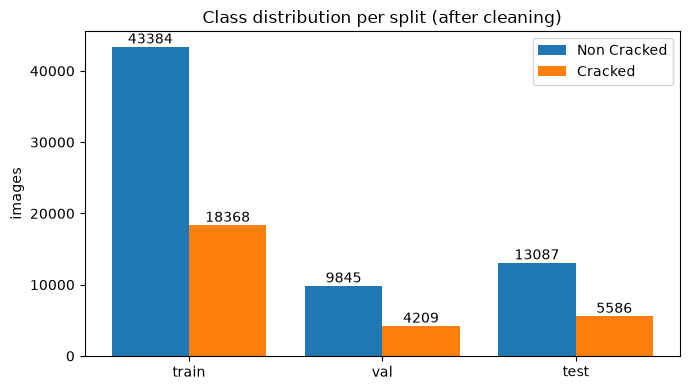

In [11]:
counts = np.array([np.bincount(y, minlength=2) for y in splits])   # columns: Non Cracked, Cracked
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.2, counts[:, 0], 0.4, label='Non Cracked')
ax.bar(x + 0.2, counts[:, 1], 0.4, label='Cracked')
for i in range(3):
    ax.text(i - 0.2, counts[i, 0], counts[i, 0], ha='center', va='bottom')
    ax.text(i + 0.2, counts[i, 1], counts[i, 1], ha='center', va='bottom')
ax.set_xticks(x); ax.set_xticklabels(['train', 'val', 'test'])
ax.set_ylabel('images'); ax.set_title('Class distribution per split (after cleaning)')
ax.legend(); plt.tight_layout(); plt.show()

**Observations:** The dataset is imbalanced: ~70% Non Cracked vs ~30% Cracked, and the ratio is the same in train, validation and test.<br>
**Implication:** A model that always predicts "Non Cracked" would reach ~70% accuracy, so this is our baseline. We use class weights in the loss and will also report the confusion matrix, precision, recall and F1 beside accuracy.

### Sample images

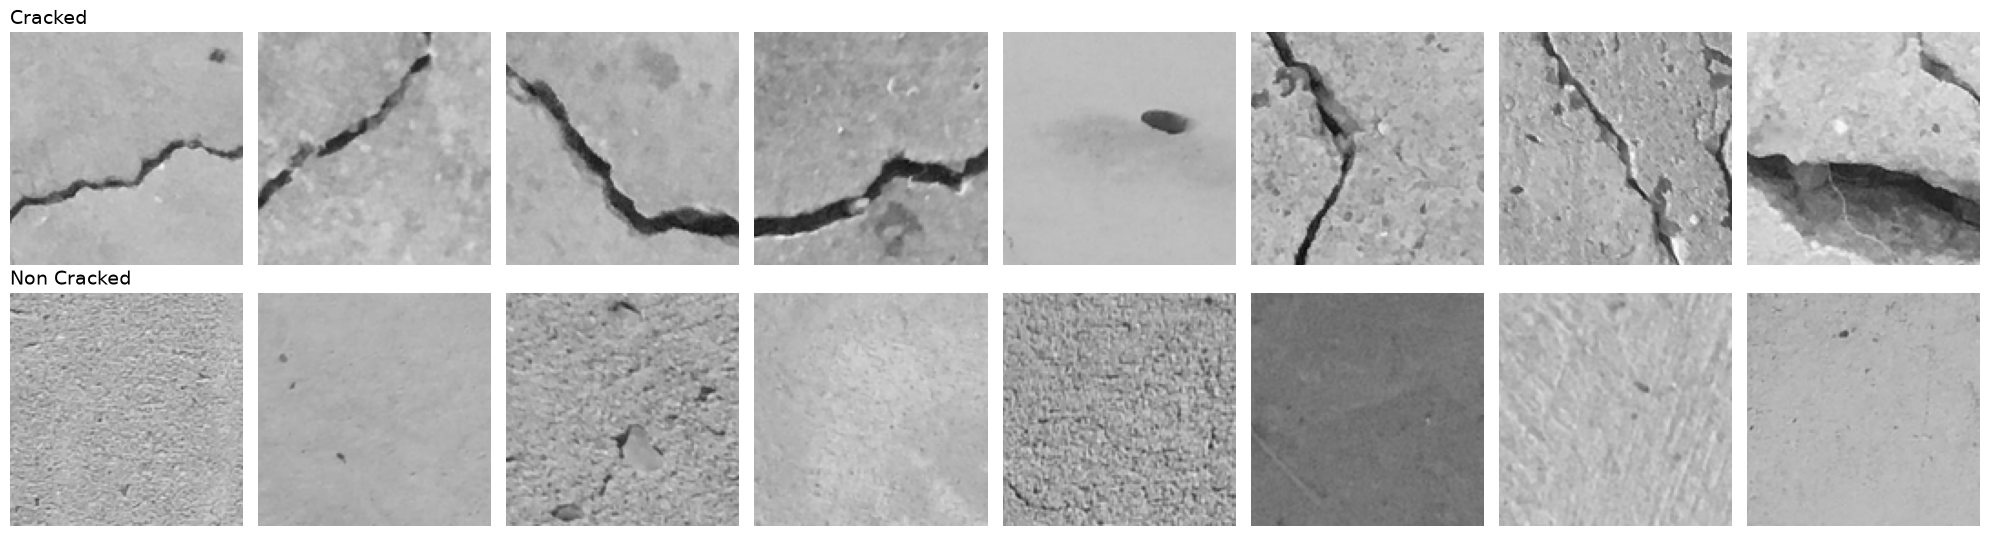

In [12]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(2, 8, figsize=(20, 5.5))
for r, (c, name) in enumerate([(1, 'Cracked'), (0, 'Non Cracked')]):
    for j, i in enumerate(rng.choice(np.where(y_train == c)[0], 8, replace=False)):
        ax[r, j].imshow(X_train[i], cmap='gray', vmin=0, vmax=255)
        ax[r, j].axis('off')
    ax[r, 0].set_title(name, loc='left', fontsize=14)
plt.tight_layout(); plt.show()

**Observations:** Cracked images show thin dark irregular lines on a lighter surface. Non Cracked images show plain or rough concrete textures with small dark spots and scratches that can look like cracks.<br>
**Implication:** The model must learn line shapes, not just dark pixels. Rough textures are the likely source of false positives.

### Pixel statistics per class

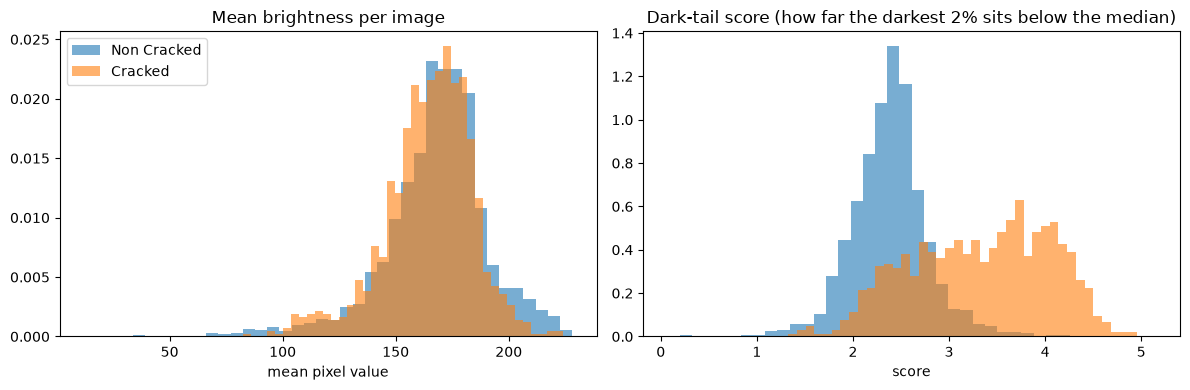

In [13]:
sub = np.random.default_rng(0).choice(len(X_train), 4000, replace=False)
flat = X_train[sub].reshape(len(sub), -1)
lab = y_train[sub]
brightness = flat.mean(1)
dark_tail = (np.median(flat, 1) - np.percentile(flat, 2, axis=1)) / (flat.std(1) + 1e-6)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, name in [(0, 'Non Cracked'), (1, 'Cracked')]:
    ax[0].hist(brightness[lab == c], bins=40, alpha=0.6, density=True, label=name)
    ax[1].hist(dark_tail[lab == c],  bins=40, alpha=0.6, density=True, label=name)
ax[0].set_title('Mean brightness per image'); ax[0].set_xlabel('mean pixel value')
ax[1].set_title('Dark-tail score (how far the darkest 2% sits below the median)')
ax[1].set_xlabel('score'); ax[0].legend(); plt.tight_layout(); plt.show()

**Observations:** Mean brightness is almost identical for both classes, so overall brightness is not a useful feature. The dark-tail score separates them better: Non Cracked peaks around 2.4, Cracked is centered around 3.5–4. The two distributions still overlap.<br>
**Implication:** Cracks appear as a small group of very dark pixels. The overlap (faint or thin cracks) means a simple threshold is not enough and a trained model is needed.

### Original image sizes by class

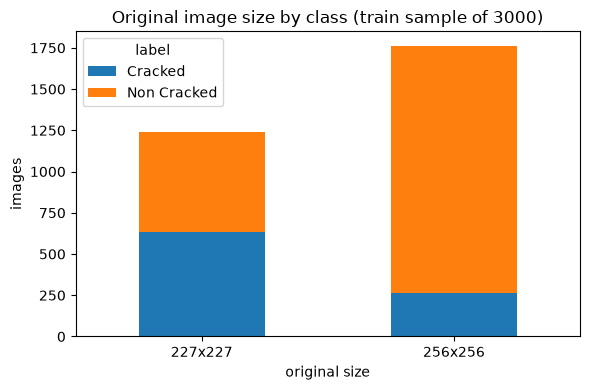

In [14]:
def orig_size(p):
    with Image.open(os.path.join(ROOT, p)) as im:
        return f'{im.size[0]}x{im.size[1]}'

samp = train_df.sample(3000, random_state=0)
with ThreadPoolExecutor(8) as ex:
    sizes = list(ex.map(orig_size, samp['image_path']))
tab = pd.crosstab(pd.Series(sizes, index=samp.index, name='original size'), samp['label'])
tab.plot(kind='bar', stacked=True, figsize=(6, 4), rot=0,
        title='Original image size by class (train sample of 3000)')
plt.ylabel('images'); plt.tight_layout(); plt.show()

**Observations:** Images come in two sizes, 227x227 and 256x256. About half of the 227x227 images are Cracked, but only ~15% of the 256x256 images are.<br>
**Implication:** Image size is correlated with the label, so it could become a shortcut. Resizing everything to 128x128 hides the original size, which reduces this risk.

### Effect of resizing: 128px vs 64px

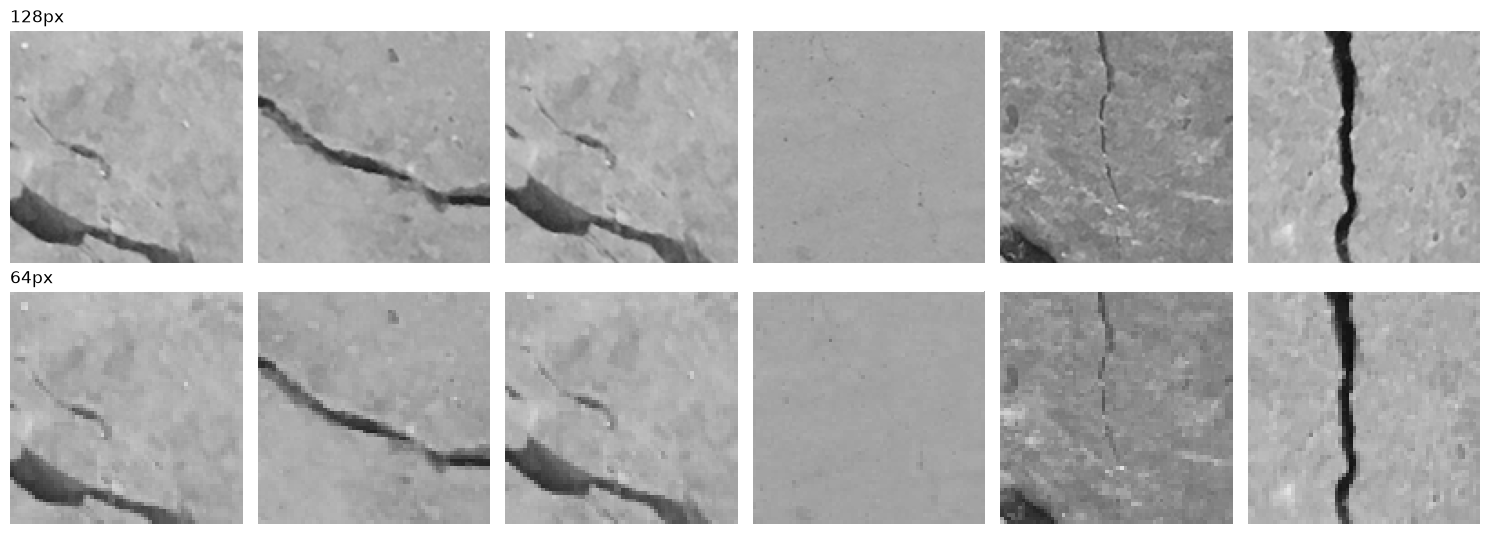

In [15]:
idx = np.where(y_train == 1)[0][:6]
fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
for j, i in enumerate(idx):
    ax[0, j].imshow(X_train[i], cmap='gray', vmin=0, vmax=255); ax[0, j].axis('off')
    ax[1, j].imshow(cv2.resize(X_train[i], (64, 64), interpolation=cv2.INTER_AREA),
                    cmap='gray', vmin=0, vmax=255); ax[1, j].axis('off')
ax[0, 0].set_title('128px', loc='left'); ax[1, 0].set_title('64px', loc='left')
plt.tight_layout(); plt.show()

**Observations:** At 64px, thin cracks become faint and pixelated and some almost disappear. At 128px they stay clearly visible.<br>
**Decision:** We use 128x128. It keeps fine cracks, while the LSTM still gets a manageable sequence of 128 time steps.

# Model and Training Code

### Dataset Class
Applies scaling to [0,1] and standardization. Each image of shape (128, 128) is treated as 128 time steps with 128 features.

In [16]:
class CrackDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float() / 255.0   # 0-255 -> 0-1
        x = (x - mean) / std                              # standardize
        return x, torch.tensor(self.y[i])                 # x shape: (128, 128) = (timesteps, features)

### Data Loaders
Create batches for train / validation / test.

In [17]:
def make_loader(X, y, batch_size, shuffle=False):
    return DataLoader(CrackDataset(X, y), batch_size=batch_size, shuffle=shuffle,
                    pin_memory=(device == 'cuda'))

def get_loaders(batch_size):          # full data, for the final run
    return (make_loader(X_train, y_train, batch_size, True),
            make_loader(X_val,   y_val,   batch_size),
            make_loader(X_test,  y_test,  batch_size))

### Training Function
Optimizer and scheduler selection, one-epoch routine, and the `training` function that saves the best model by validation accuracy.

In [18]:
def get_optimizer(name, params, lr, weight_decay):
    if name == 'SGD':     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == 'Adam':    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == 'RMSprop': return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f'Unknown optimizer: {name}')

def get_scheduler(name, optimizer, epochs):
    if name == 'step':   return torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.5)
    if name == 'cosine': return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return None

def run_epoch(model, loader, criterion, optimizer=None):
    '''One pass over the data. Trains if an optimizer is given, otherwise only evaluates.'''
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # keeps LSTM gradients stable
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

def training(model, train_loader, val_loader, epochs, optimizer_name, lr,
            weight_decay, scheduler_name=None, trial=None, save_path=None,
            class_weights=None, verbose=True):
    model.to(device)
    w = torch.tensor(class_weights, dtype=torch.float32).to(device) if class_weights else None
    criterion = nn.CrossEntropyLoss(weight=w)
    optimizer = get_optimizer(optimizer_name, model.parameters(), lr, weight_decay)
    scheduler = get_scheduler(scheduler_name, optimizer, epochs)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val = 0.0

    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        if scheduler: scheduler.step()

        for k, v in zip(history, (tl, ta, vl, va)):
            history[k].append(v)

        if save_path and va > best_val:          # keep the best model by validation accuracy
            best_val = va
            torch.save(model.state_dict(), save_path)

        if verbose:
            print(f'Epoch {ep+1}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')

        if trial is not None:                    # only used by Optuna
            trial.report(va, ep)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return history

# Hyperparameter Search (Optuna)

### Setup

In [19]:
SEARCH_TRAIN, SEARCH_VAL, SEARCH_EPOCHS = 30000, 5000, 8

i_tr, _ = train_test_split(np.arange(len(y_train)), train_size=SEARCH_TRAIN, stratify=y_train, random_state=SEED)
i_va, _ = train_test_split(np.arange(len(y_val)),   train_size=SEARCH_VAL,   stratify=y_val,   random_state=SEED)
Xs_tr, ys_tr = X_train[i_tr], y_train[i_tr]
Xs_va, ys_va = X_val[i_va],   y_val[i_va]

class_weights = (len(y_train) / (2 * np.bincount(y_train))).tolist()

### Search space

In [20]:
def suggest_params(trial):
    opt = trial.suggest_categorical('optimizer', ['SGD', 'Adam', 'RMSprop'])
    if opt == 'SGD':
        lr = trial.suggest_float('lr_sgd', 1e-3, 1e-1, log=True)
    else:
        lr = trial.suggest_float('lr_adaptive', 1e-4, 1e-2, log=True)
    return {
        'batch_size': trial.suggest_categorical('batch_size', [32, 64, 128]),
        'num_layers': trial.suggest_int('num_layers', 1, 3),
        'hidden_size': trial.suggest_categorical('hidden_size', [64, 128]),
        'dropout': trial.suggest_float('dropout', 0.0, 0.5, step=0.1),
        'optimizer': opt,
        'lr': lr,
        'weight_decay': trial.suggest_float('weight_decay', 1e-6, 1e-3, log=True),
        'scheduler': trial.suggest_categorical('scheduler', ['none', 'step', 'cosine']),
    }

### Objective

In [21]:
def objective(trial):
    p = suggest_params(trial)
    torch.manual_seed(SEED)
    train_loader = make_loader(Xs_tr, ys_tr, p['batch_size'], shuffle=True)
    val_loader   = make_loader(Xs_va, ys_va, p['batch_size'])
    model = LSTMClassifier(input_size=IMG_SIZE, hidden_size=p['hidden_size'],
                        num_layers=p['num_layers'], dropout=p['dropout'])
    history = training(model, train_loader, val_loader, epochs=SEARCH_EPOCHS,
                    optimizer_name=p['optimizer'], lr=p['lr'],
                    weight_decay=p['weight_decay'], scheduler_name=p['scheduler'],
                    trial=trial, class_weights=class_weights, verbose=False)
    return max(history['val_acc'])

### Study

In [22]:
study = optuna.create_study(
    study_name='lstm_cracks', storage='sqlite:///optuna_lstm.db', load_if_exists=True,
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2))

study.optimize(objective, n_trials=2)      # smoke test first, then raise to about 20
#study.optimize(objective, n_trials=20)
print('best val acc:', study.best_value)
print(study.best_params)

[I 2026-11-22 20:46:31,134] Using an existing study with `study_name='lstm_cracks'` instead of creating a new one.
[W 2026-11-22 20:46:31,189] Trial 2 failed with parameters: {'optimizer': 'Adam', 'lr_adaptive': 0.0015751320499779737, 'batch_size': 32, 'num_layers': 3, 'hidden_size': 128, 'dropout': 0.0, 'weight_decay': 0.0008123245085588687, 'scheduler': 'none'} because of the following error: NameError("name 'LSTMClassifier' is not defined").
Traceback (most recent call last):
  File "/home/nabil_darwish/miniconda3/lib/python3.14/site-packages/optuna/study/_optimize.py", line 210, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_3175472/1371273820.py", line 6, in objective
    model = LSTMClassifier(input_size=IMG_SIZE, hidden_size=p['hidden_size'],
            ^^^^^^^^^^^^^^
NameError: name 'LSTMClassifier' is not defined
[W 2026-11-22 20:46:31,190] Trial 2 failed with value None.


NameError: name 'LSTMClassifier' is not defined